## Load the data

In [182]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train_df = pd.read_csv("mnist_train.csv")
test_df = pd.read_csv("mnist_test.csv")

x_train = train_df.drop(columns = "label").to_numpy()
y_train = train_df["label"].to_numpy()

x_test = test_df.drop(columns= "label").to_numpy()
y_test = test_df["label"].to_numpy()

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

(60000, 784) (60000,)
(10000, 784) (10000,)


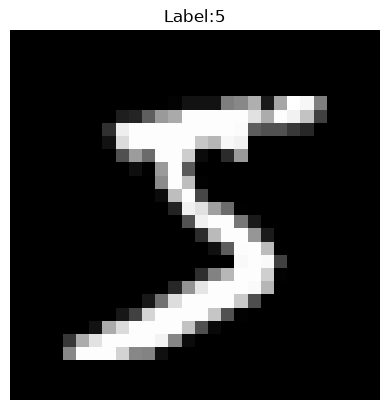

In [183]:
idx = 0
plt.imshow(x_train[idx].reshape(28,28),cmap="gray")
plt.title(f"Label:{y_train[idx]}")
plt.axis("off")
plt.show()

## Normalize the pixels

In [184]:
x_train = x_train.astype("float32")/255.0
x_test = x_test.astype("float32")/255.0

print(x_train.min(), x_train.max())

0.0 1.0


## One-hot encode the labels

In [185]:
y_train_oh = np.eye(10)[y_train]
y_test_oh = np.eye(10)[y_test]

print(y_train_oh.shape, y_test_oh.shape)
print(y_train[0], y_train_oh[0])

(60000, 10) (10000, 10)
5 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## Activation and loss functions

In [186]:
def relu(z):
    return np.maximum(0,z)

def relu_derivative(z):
    return (z > 0).astype(float)

def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z/np.sum(exp_z, axis=1, keepdims=True)

def cross_entropy(y_pred, y_true):
    return -np.mean(np.sum(y_true * np.log(y_pred + 1e-8), axis=1))

In [187]:
print(relu(np.array([-2, 0, 3])))
print(relu_derivative(np.array([-2, 0, 3])))
print(softmax(np.array([[1, 2, 3]])).sum())

[0 0 3]
[0. 0. 1.]
0.9999999999999999


## Initialize weights and biases

In [188]:
def init_params(layer_sizes):
    params = {}
    for i in range(1, len(layer_sizes)):
        n_in = layer_sizes[i - 1]
        n_out = layer_sizes[i]
        params[f"w{i}"] = np.random.randn(n_in, n_out) * np.sqrt(2 / n_in)
        params[f"b{i}"] = np.zeros((1, n_out))
    return params

In [189]:
params = init_params([784, 128, 64, 10])
for k, v in params.items():
    print(k, v.shape)

w1 (784, 128)
b1 (1, 128)
w2 (128, 64)
b2 (1, 64)
w3 (64, 10)
b3 (1, 10)


## Forward pass

In [190]:
def forward(x, params):
    L = len(params) // 2
    cache = {"A0": x}
    A = x
    for i in range(1, L + 1):
        Z = A @ params[f"w{i}"] + params[f"b{i}"]
        if i == L:
            A = softmax(Z)
        else:
            A = relu(Z)
        cache[f"Z{i}"] = Z
        cache[f"A{i}"] = A
    return A, cache

In [191]:
y_pred, cache = forward(x_train[:5], params)
print(y_pred.shape)
print(y_pred.sum(axis=1))


(5, 10)
[1. 1. 1. 1. 1.]


## Backward pass

In [192]:
def backward(y_true, params, cache):
    grads = {}
    L = len(params) // 2
    m = y_true.shape[0]

    dZ = cache[f"A{L}"] - y_true

    for i in range(L, 0, -1):
        A_prev = cache[f"A{i-1}"]
        grads[f"w{i}"] = A_prev.T @ dZ/m
        grads[f"b{i}"] = np.sum(dZ, axis=0, keepdims=True) / m
        if i > 1:
            dA_prev = dZ @ params[f"w{i}"].T
            dZ = dA_prev * relu_derivative(cache[f"Z{i-1}"])
    return grads

In [193]:
grads = backward(y_train_oh[:5], params, cache)
for k in params:
    print(k, params[k].shape, grads[k].shape)
    

w1 (784, 128) (784, 128)
b1 (1, 128) (1, 128)
w2 (128, 64) (128, 64)
b2 (1, 64) (1, 64)
w3 (64, 10) (64, 10)
b3 (1, 10) (1, 10)


## Update the parameters

In [194]:
def update_params(params, grads, lr):
    for k in params:
        params[k] -= lr * grads[k]
    return params

## Accuracy

In [195]:
def accuracy(y_pred, y_labels):
    preds = np.argmax(y_pred, axis=1)
    return np.mean(preds == y_labels)


## Train the network

In [196]:
np.random.seed(42)
params = init_params([784, 128, 64, 10])
lr = 0.1
epochs = 15
batch_size = 64
m = x_train.shape[0]

loss_history, acc_history = [], []

for epoch in range(epochs):
    perm = np.random.permutation(m)
    x_shuf, y_shuf = x_train[perm], y_train_oh[perm]

    for start in range(0, m, batch_size):
        x_batch = x_shuf[start:start + batch_size]
        y_batch = y_shuf[start:start + batch_size]

        y_pred, cache = forward(x_batch, params)
        grads = backward(y_batch, params, cache)
        params = update_params(params, grads, lr)

    y_pred_full, _ = forward(x_train, params)
    loss = cross_entropy(y_pred_full, y_train_oh)
    acc = accuracy(y_pred_full, y_train)
    loss_history.append(loss)
    acc_history.append(acc)
    print(f"Epoch {epoch+1}/{epochs} - loss: {loss:.4f} - acc: {acc:.4f}")


Epoch 1/15 - loss: 0.1741 - acc: 0.9498
Epoch 2/15 - loss: 0.1258 - acc: 0.9631
Epoch 3/15 - loss: 0.0978 - acc: 0.9698
Epoch 4/15 - loss: 0.0858 - acc: 0.9739
Epoch 5/15 - loss: 0.0581 - acc: 0.9832
Epoch 6/15 - loss: 0.0466 - acc: 0.9869
Epoch 7/15 - loss: 0.0387 - acc: 0.9886
Epoch 8/15 - loss: 0.0312 - acc: 0.9917
Epoch 9/15 - loss: 0.0496 - acc: 0.9840
Epoch 10/15 - loss: 0.0242 - acc: 0.9933
Epoch 11/15 - loss: 0.0210 - acc: 0.9942
Epoch 12/15 - loss: 0.0224 - acc: 0.9938
Epoch 13/15 - loss: 0.0130 - acc: 0.9974
Epoch 14/15 - loss: 0.0128 - acc: 0.9972
Epoch 15/15 - loss: 0.0105 - acc: 0.9980


## Evaluate on the test set

In [197]:
y_test_pred, _ = forward(x_test, params)

test_loss = cross_entropy(y_test_pred, y_test_oh)
test_acc = accuracy(y_test_pred, y_test)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

print(f"Train accuracy: {acc_history[-1]:.4f}")

Test loss: 0.0822
Test accuracy: 0.9765
Train accuracy: 0.9980


## Plot loss and accuracy

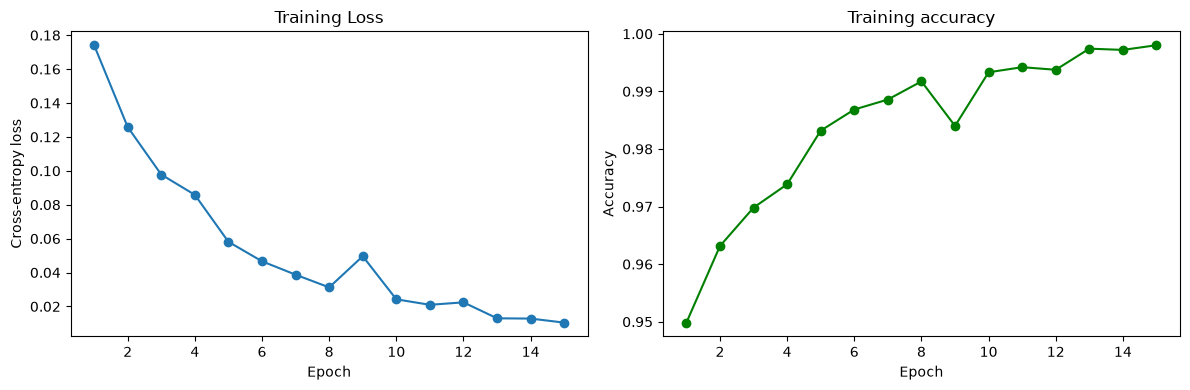

In [198]:
epochs_range = range(1, epochs + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs_range, loss_history, marker="o")
ax[0].set_title("Training Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Cross-entropy loss")

ax[1].plot(epochs_range, acc_history, marker="o", color="green")
ax[1].set_title("Training accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")

plt.tight_layout()
plt.show()

## Sample predictions

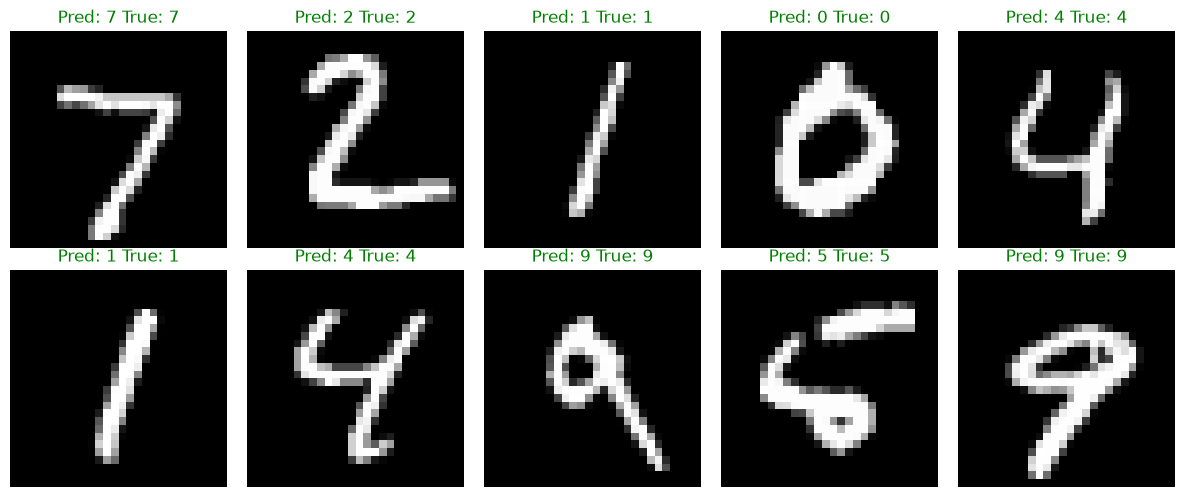

In [199]:
test_preds = np.argmax(y_test_pred, axis=1)

fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for i, a in enumerate(ax.flat):
    a.imshow(x_test[i].reshape(28,28), cmap="gray")
    color = "green" if test_preds[i] == y_test[i] else "red"
    a.set_title(f"Pred: {test_preds[i]} True: {y_test[i]}", color=color)
    a.axis("off")
plt.tight_layout()
plt.show()

## Misclassified images

Wrong predictions: 235 out of 10000


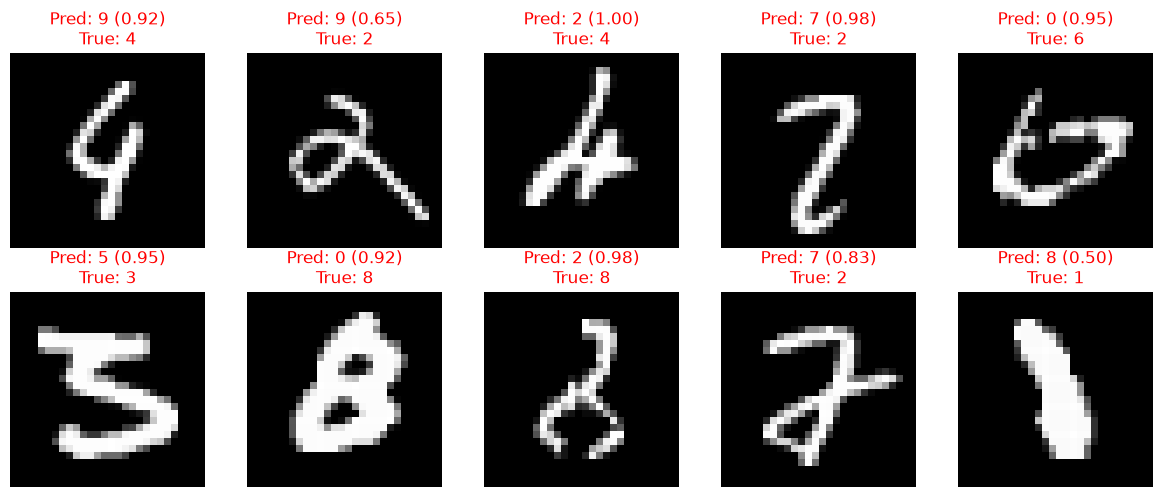

In [200]:
wrong = np.where(test_preds != y_test)[0]
print(f"Wrong predictions: {len(wrong)} out of {len(y_test)}")

fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for a, i in zip(ax.flat, wrong[:10]):
    a.imshow(x_test[i].reshape(28,28), cmap="gray")
    conf = y_test_pred[i, test_preds[i]]
    a.set_title(f"Pred: {test_preds[i]} ({conf:.2f})\nTrue: {y_test[i]}", color="red")
    a.axis("off")
plt.tight_layout()
plt.show()

## Confusion matrix and per-digit accuracy

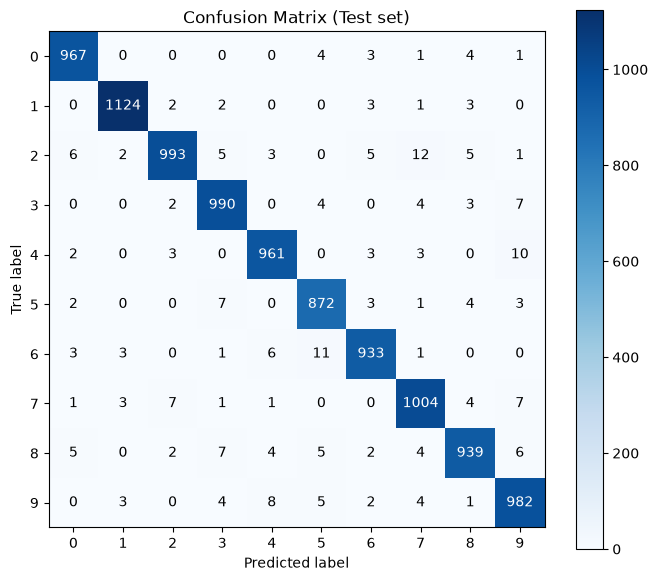

Digit 0: 0.9867
Digit 1: 0.9903
Digit 2: 0.9622
Digit 3: 0.9802
Digit 4: 0.9786
Digit 5: 0.9776
Digit 6: 0.9739
Digit 7: 0.9767
Digit 8: 0.9641
Digit 9: 0.9732


In [201]:
conf_matrix = np.zeros((10, 10), dtype=int)
for t, p in zip(y_test, test_preds):
    conf_matrix[t, p] += 1

plt.figure(figsize=(8, 7))
plt.imshow(conf_matrix, cmap="Blues")
plt.colorbar()
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix (Test set)")

for i in range(10):
    for j in range(10):
        color = "white" if conf_matrix[i, j] > conf_matrix.max() / 2 else "black"
        plt.text(j, i, conf_matrix[i, j], ha="center", va="center", color=color)
plt.show()

per_class_acc = np.diag(conf_matrix) / conf_matrix.sum(axis=1)
for d in range(10):
    print(f"Digit {d}: {per_class_acc[d]:.4f}")

## Conclusions
- An ANN (784 → 128 → 64 → 10, ReLU + softmax) was built from scratch with NumPy to recognise handwritten digits from MNIST.
- The model is 97.65% accurate on the test images: 9,765 out of 10,000 were classified correctly.
- Training accuracy reached 99.8%, so the model overfits slightly but still works well on new images.
- Digit 1 is the easiest to recognise (99.0%), while 2 and 8 are the hardest (about 96%).
- Most mistakes are between digits that look alike when written messily, like 2 and 7, 6 and 5, and 4 and 9.